# NetworkTrace — Community Detection

## Objective

The objective of this phase is to identify communities
within a social network using graph-based community
detection algorithms.

The GPlus ego-network dataset provides known social
circles that can later be used as reference communities
for evaluation.

In this phase, we first apply the Louvain community
detection algorithm to one ego network.

In [4]:
%pip install networkx pandas matplotlib

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.1 MB 2.1 MB/s eta 0:00:01
   -------------- ------------------------- 0.8/2.1 MB 1.8 MB/s eta 0:00:01
   ------------------- -------------------- 1.0/2.1 MB 1.7 MB/s eta 0:00:01
   ------------------------ --------------- 1.3/2.1 MB 1.6 MB/s eta 0:00:01
   ---------------------------------- ----- 1.8/2.1 MB 1.6 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 1.6 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
from pathlib import Path

import pandas as pd
import networkx as nx
# If the notebook kernel does not have it installed:
# %pip install networkx
import matplotlib.pyplot as plt

EGO_ID = "100129275726588145876"

DATA_DIR = Path("../data/processed")

print("NetworkTrace")
print("Ego Network:", EGO_ID)

NetworkTrace
Ego Network: 100129275726588145876


## Load Network Data

We load only the selected ego network rather than the
entire 26+ million edge dataset. This allows us to test
and validate the methodology before scaling to all
132 ego networks.

In [6]:
edges_path = DATA_DIR / "edges.csv"

edges_df = pd.read_csv(
    edges_path,
    dtype={
        "source": "string",
        "target": "string",
        "ego_id": "string"
    }
)

ego_edges = edges_df[
    edges_df["ego_id"] == EGO_ID
].copy()

print("Edges:", f"{len(ego_edges):,}")
ego_edges.head()

Edges: 151,766


,source,target,ego_id
0,116374117927631468606,101765416973555767821,100129275726588145876
1,112188647432305746617,107727150903234299458,100129275726588145876
2,116719211656774388392,100432456209427807893,100129275726588145876
3,117421021456205115327,101096322838605097368,100129275726588145876
4,116407635616074189669,113556266482860931616,100129275726588145876


In [7]:
#build the graph 
G = nx.from_pandas_edgelist(
    ego_edges,
    source="source",
    target="target"
)

print("Nodes:", f"{G.number_of_nodes():,}")
print("Edges:", f"{G.number_of_edges():,}")

Nodes: 1,650
Edges: 151,766


In [11]:
import community as community_louvain

In [9]:
%pip install python-louvain

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for python-louvain: filename=python_louvain-0.16-py3-none-any.whl size=9474 sha256=d428a2b3a2577f415458ce05cbd0f4cc6fb4a1cf79b53f99aad99d20b05cf33b
  Stored in directory: c:\users\utkar\appdata\local\pip\cache\wheels\ae\22\72\95110a1ec427d179bc90c8ae1bcf245568db417ac2f34dee63
Successfully built python-louvain
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
#run louvain
partition = community_louvain.best_partition(
    G,
    random_state=42
)

print(
    "Number of detected communities:",
    len(set(partition.values()))
)

Number of detected communities: 8


In [13]:
modularity = community_louvain.modularity(
    partition,
    G
)

print("Louvain modularity:", modularity)

Louvain modularity: 0.3199837537559192


In [14]:
from collections import Counter

community_sizes = Counter(
    partition.values()
)

community_sizes_df = pd.DataFrame(
    community_sizes.items(),
    columns=["community_id", "size"]
).sort_values(
    "size",
    ascending=False
)

community_sizes_df.head(10)

,community_id,size
0,0,814
1,1,666
2,2,115
3,3,46
4,6,3
5,7,2
6,4,2
7,5,2


In [15]:
from collections import Counter

community_sizes = Counter(
    partition.values()
)

community_sizes_df = pd.DataFrame(
    community_sizes.items(),
    columns=["community_id", "size"]
).sort_values(
    "size",
    ascending=False
)

community_sizes_df.head(10)

,community_id,size
0,0,814
1,1,666
2,2,115
3,3,46
4,6,3
5,7,2
6,4,2
7,5,2


In [16]:
# result cell 
print("===== LOUVAIN RESULTS =====")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Detected communities:", len(set(partition.values())))
print("Modularity:", round(modularity, 4))

===== LOUVAIN RESULTS =====
Nodes: 1650
Edges: 151766
Detected communities: 8
Modularity: 0.32


In [17]:
#communityt size table
from collections import Counter

community_sizes = Counter(partition.values())

community_sizes_df = pd.DataFrame(
    community_sizes.items(),
    columns=["community_id", "size"]
).sort_values(
    "size",
    ascending=False
).reset_index(drop=True)

community_sizes_df.head(10)

,community_id,size
0,0,814
1,1,666
2,2,115
3,3,46
4,6,3
5,7,2
6,4,2
7,5,2


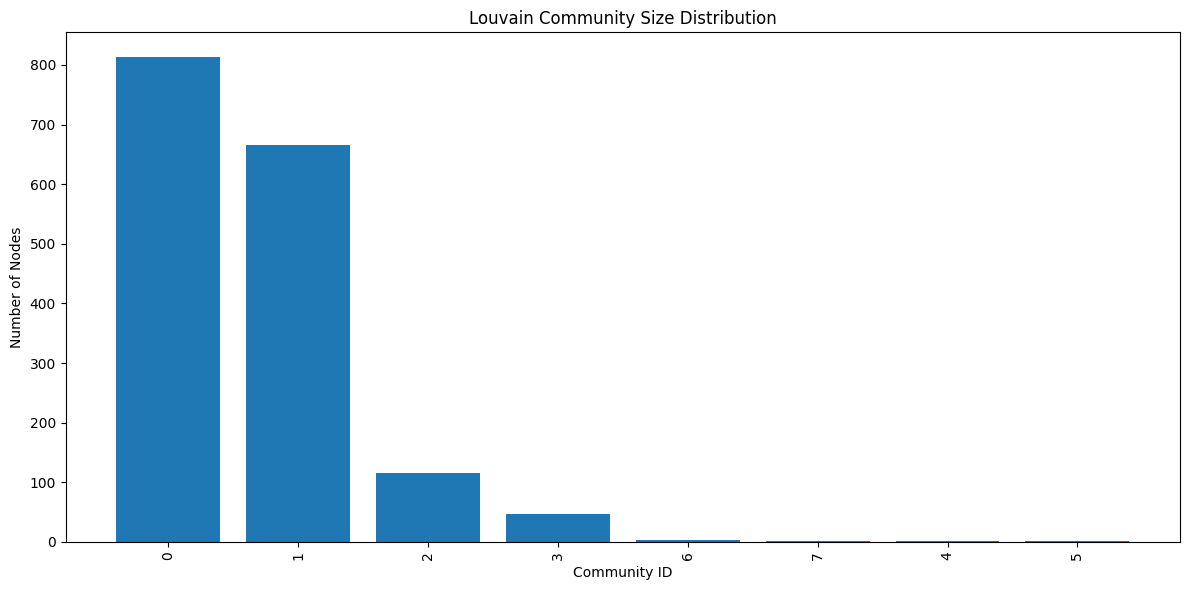

In [18]:
#visulize commmunity size 
plt.figure(figsize=(12, 6))

plt.bar(
    community_sizes_df["community_id"].astype(str),
    community_sizes_df["size"]
)

plt.xlabel("Community ID")
plt.ylabel("Number of Nodes")
plt.title("Louvain Community Size Distribution")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

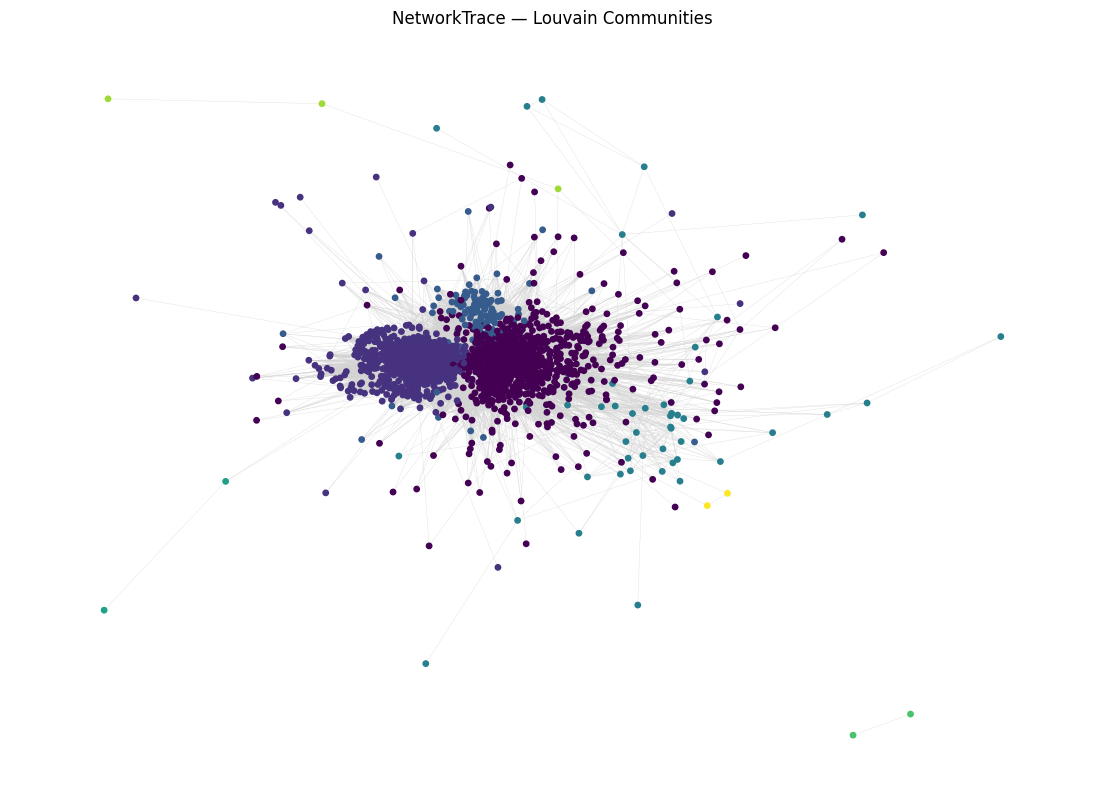

In [19]:
#community colored network
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.15
)

node_colors = [
    partition[node]
    for node in G.nodes()
]

nx.draw_networkx(
    G,
    pos,
    node_size=15,
    node_color=node_colors,
    with_labels=False,
    edge_color="lightgray",
    width=0.2
)

plt.title("NetworkTrace — Louvain Communities")
plt.axis("off")
plt.show()

In [20]:
#save louvain results
from pathlib import Path

RESULTS_DIR = Path("../results/community_detection")
RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [21]:
louvain_results = pd.DataFrame(
    [
        {
            "ego_id": EGO_ID,
            "node_id": node,
            "community_id": community
        }
        for node, community in partition.items()
    ]
)

louvain_results.to_csv(
    RESULTS_DIR / "louvain_communities.csv",
    index=False
)

community_sizes_df.to_csv(
    RESULTS_DIR / "louvain_community_sizes.csv",
    index=False
)

print("Results saved.")

Results saved.


In [22]:
circles_path = Path(
    "../data/raw/gplus"
) / f"{EGO_ID}.circles"

circles = {}

with open(circles_path, "r", encoding="utf-8") as f:
    for line in f:
        parts = line.strip().split()

        if len(parts) >= 2:
            circle_id = parts[0]
            members = set(parts[1:])
            circles[circle_id] = members

print("Known circles:", len(circles))

for circle_id, members in circles.items():
    print(circle_id, "→", len(members), "members")

Known circles: 2
Az1VWXrXzeg → 334 members
KnPjU8oQM2z → 485 members


In [23]:
circle_ids = list(circles.keys())

if len(circle_ids) >= 2:

    overlap = circles[circle_ids[0]].intersection(
        circles[circle_ids[1]]
    )

    print(
        "Members in both circles:",
        len(overlap)
    )

Members in both circles: 333
